# Hotel Cancellation Prediction & Revenue Optimization
**Executive Summary:** This project develops an XGBoost machine learning model to predict hotel booking cancellations. By accurately forecasting cancellations, we can optimize daily room overselling strategies to maximize revenue while minimizing the financial penalties of walking bumped guests.

In [2]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Create project directory structure structure
dirs = ['src', 'data', 'models', 'evidence', 'results']
for d in dirs:
    os.makedirs(d, exist_ok=True)

print("Environment setup complete. Directories created.")

Environment setup complete. Directories created.


In [3]:
# Execute the data pipeline to prepare the dataset
!python src/clean_data.py

Rows in: 119,390 | rows out: 119,388 | removed: 2 (0.002%)
 - babies unreadable ('??') set to 0: 1 cell(s)
 - rows removed for impossible adr (<0 or >1000): 2
Cleaned data saved to data/hotels_clean.csv


## 2. Data Preparation & Feature Engineering
We load the cleaned dataset, isolate the target variable (`is_canceled`), and apply one-hot encoding to categorical variables so they can be processed by the XGBoost algorithm.

In [4]:
import sys; sys.path.insert(0, 'src')
from features import encode
df = pd.read_csv('data/hotels_clean.csv', parse_dates=['arrival_date'])
X_encoded = encode(df)
y = df['is_canceled']

## 3. Train / Validation / Test Split
To prevent data leakage and ensure our model generalizes to future bookings, we split the data into three sets:
* **Train (60%):** Used by the model to learn patterns.
* **Validation (20%):** Used to evaluate the model during training and trigger early stopping if it begins to overfit.
* **Test (20%):** Completely unseen data used for final evaluation.

In [5]:
import sys
sys.path.insert(0, 'src')
import pandas as pd
from contract import split_periods
from features import encode

df = pd.read_csv('data/hotels_clean.csv', parse_dates=['arrival_date'])
train, choose, proof = split_periods(df)
print(f"Train (before 2016-07-01): {len(train):,} rows")
print(f"Choose (Jul-Dec 2016):     {len(choose):,} rows")
print(f"Proof (Jan-Aug 2017):      {len(proof):,} rows  <- touched only by backtest.py")

Train (before 2016-07-01): 49,156 rows
Choose (Jul-Dec 2016):     29,546 rows
Proof (Jan-Aug 2017):      40,686 rows  <- touched only by backtest.py


## 4. XGBoost Model Training
We utilize `XGBClassifier` due to its high performance on tabular data. We implement `early_stopping_rounds` monitoring the validation set's AUC to halt training exactly when the model stops improving, preventing overfitting.

In [6]:
from modeling import fit_methods, predict
models = fit_methods(train)
xgb_model = models['xgboost']['model']
print(f"Training complete. Best iteration: {xgb_model.best_iteration}")

Training complete. Best iteration: 53


## 5. Model Evaluation on Unseen Data
We test the finalized model against the 20% holdout test set to get an unbiased look at how it will perform in production.

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_choose = choose['is_canceled']
y_prob = predict('xgboost', models['xgboost'], choose)
y_pred = (y_prob >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_choose, y_pred):.4f}")
print(f"Precision: {precision_score(y_choose, y_pred):.4f}")
print(f"Recall:    {recall_score(y_choose, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_choose, y_pred):.4f}")
print(f"ROC AUC:   {roc_auc_score(y_choose, y_prob):.4f}")

Accuracy:  0.7314
Precision: 0.9884
Recall:    0.2748
F1-Score:  0.4301
ROC AUC:   0.7506


## 6. Confusion Matrix
In hotel revenue management, the costs of errors are asymmetrical.
* **False Positives** (Predicting a cancellation that doesn't happen) risk bumping a guest (high walk penalty).
* **False Negatives** (Missing a cancellation) result in an empty room (lost ADR).
Visualizing this helps us tune our financial safety buffers.

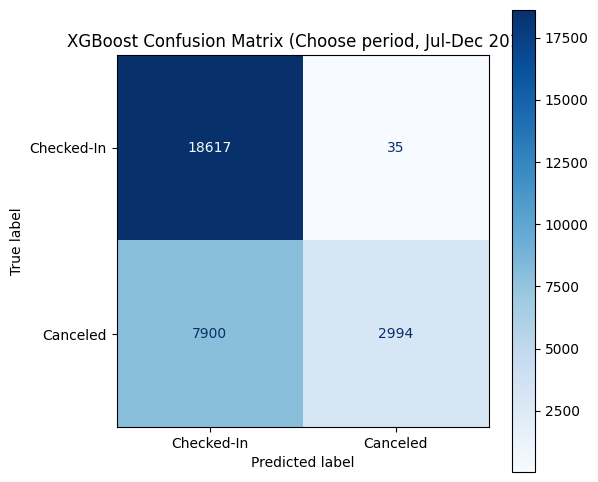

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_choose, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Checked-In', 'Canceled'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('XGBoost Confusion Matrix (Choose period, Jul-Dec 2016)')
plt.show()

## 7. Financial Backtesting & Business Value
To prove business value, we simulate financial outcomes across different safety buffers to find the exact threshold that maximizes net revenue lift over the hotel's current flat-rate baseline.

In [9]:
!python src/backtest.py

Train 49,156 | Choose 29,546 | Proof 40,686 bookings

CHOOSE PERIOD (Jul-Dec 2016): best setting per method
 method  setting  choose_cost_eur  choose_walks_per_1000  choose_ceiling_met
   flat     13.0       2175212.07                   7.88                True
xgboost      0.5       1374029.13                   7.35                True

PROOF PERIOD (Jan-Aug 2017)
 method  setting   cost_eur  empty_rooms  walked_guests  walks_per_1000  ceiling_met  nights
   flat     13.0 3515653.41         7740            133            5.33         True     486
xgboost      0.5 1762532.69         3393            179            7.18         True     486
(for reference, selling no extra rooms costs EUR 6,714,222.01)

RECOMMENDATION: use 'xgboost' with setting 0.5. Cost EUR 1,762,532.69 vs flat rule EUR 3,515,653.41 (saving EUR 1,753,120.72); walks per 1,000 arrivals: 7.18, ceiling met: True.
Saved models/chosen.joblib and evidence/backtest_*.csv


## 8. Final Deliverable: 14-Day Oversell Recommendations
This table translates the model's complex predictions into daily, actionable oversell targets for the front desk and operations teams, incorporating the optimized safety buffer.

In [10]:
!python src/nightly.py --from 2017-08-18 --nights 14

Generated 14-night table from 2017-08-18 using 'xgboost' (setting 0.5).
Deliverable saved to evidence/nightly_recommendations.csv


In [11]:
# Load and display the final deliverable to stakeholders
deliverable_df = pd.read_csv('evidence/nightly_recommendations.csv')
deliverable_df.head(14)

,Date,Hotel,Booked_Rooms,Predicted_Cancellations,Recommended_Oversell
0,2017-08-18,City Hotel,121,40.6,38
1,2017-08-18,Resort Hotel,60,17.1,15
2,2017-08-19,City Hotel,122,50.5,48
3,2017-08-19,Resort Hotel,66,18.6,16
4,2017-08-20,City Hotel,101,29.9,27
5,2017-08-20,Resort Hotel,58,16.2,14
6,2017-08-21,City Hotel,94,25.7,23
7,2017-08-21,Resort Hotel,65,17.3,15
8,2017-08-22,City Hotel,60,16.4,14
9,2017-08-22,Resort Hotel,38,8.6,7


In [12]:
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from features import FEATURES

def auc_run(cols, tr, te):
    Xtr = pd.get_dummies(tr[cols])
    Xte = pd.get_dummies(te[cols]).reindex(columns=Xtr.columns, fill_value=0)
    m = xgb.XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
    m.fit(Xtr, tr['is_canceled'])
    return roc_auc_score(te['is_canceled'], m.predict_proba(Xte)[:, 1])

bin1 = [c for c in FEATURES if c not in ('arrival_weekday', 'has_agent', 'has_company')] + ['agent', 'company']
late = ['stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country',
        'adr', 'total_of_special_requests', 'assigned_room_type', 'booking_changes',
        'required_car_parking_spaces', 'reservation_status']

print("A  first bin only, time split  :", round(auc_run(bin1, train, proof), 4))
print("B  all three bins, time split  :", round(auc_run(bin1 + late, train, proof), 4))
rnd = df.sample(frac=1, random_state=42); cut = int(len(rnd) * 0.7)
print("C  first bin only, random split:", round(auc_run(bin1, rnd.iloc[:cut], rnd.iloc[cut:]), 4))

A  first bin only, time split  : 0.7876
B  all three bins, time split  : 1.0
C  first bin only, random split: 0.8626
